In [5]:
import os
import json
import re
import base64
import mimetypes
import pandas as pd
import torch
from PIL import Image
from pathlib import Path
from openai import OpenAI
from IPython import display
from glob import glob
from tqdm import tqdm 
from datasets import load_dataset
from transformers import AutoProcessor, BitsAndBytesConfig
from peft import LoraConfig, PeftModel
from trl import SFTConfig, SFTTrainer
from transformers import Qwen2VLProcessor, AutoProcessor
from io import StringIO


# --------------------------------------------------------------------------- #
# Configuration
# --------------------------------------------------------------------------- #
API_BASE_URL = "http://localhost:8000/v1"
API_KEY = "EMPTY"
client = OpenAI(base_url=API_BASE_URL,api_key=API_KEY)
model = client.models.list().data[0].id
print(model)

Output/Mistral-Small-3.2-24B-Instruct-2506-lora-run1/merged-100


In [6]:
import os
import sys

# 這份 notebook 原本放在 repo root，現在搬進 notebooks/ 底下；下面 cell 裡的
# "Microsoft-JhengHei.ttf"、"images/真實碰撞構圖/*.jpg"、"交通肇事分析報告.xlsx"、
# utils.gen_utils import 等都是假設 CWD=repo root 的相對路徑。與其逐一修改每個
# cell 的路徑，這裡直接把 CWD 切回 repo root——只有「目前在 notebooks/ 底下」才切
# 一次，重複執行這個 cell（不重啟 kernel）不會往上多跳到 repo root 的上一層。
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
PROJECT_ROOT = os.getcwd()
print("Project root (CWD):", PROJECT_ROOT)
if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

Project root (CWD): /mnt/moris/Project/transport_vlm_refactor


In [ ]:
# CUDA_VISIBLE_DEVICES=0 vllm serve Output/Mistral-Small-3.2-24B-Instruct-2506-merged-2025-09-30 \
#   --tokenizer Output/Mistral-Small-3.2-24B-Instruct-2506-merged-2025-09-30 \
#   --load_format safetensors \
#   --tool-call-parser mistral \
#   --enable-auto-tool-choice

# CUDA_VISIBLE_DEVICES=1 vllm serve Output/Mistral-Small-3.2-24B-Instruct-2506-merged-2025-10-01 \
#   --tokenizer Output/Mistral-Small-3.2-24B-Instruct-2506-merged-2025-10-01 \
#   --load_format safetensors \
#   --tool-call-parser mistral \
#   --enable-auto-tool-choice

# CUDA_VISIBLE_DEVICES=1 vllm serve Output/Mistral-Small-3.2-24B-Instruct-2506-merged-2025-10-03 \
#   --tokenizer Output/Mistral-Small-3.2-24B-Instruct-2506-merged-2025-10-03 \
#   --load_format safetensors \
#   --tool-call-parser mistral \
#   --enable-auto-tool-choice

# CUDA_VISIBLE_DEVICES=0 vllm serve models/GLM-4.1V-9B-Thinking \
#   --tokenizer models/GLM-4.1V-9B-Thinking \
#   --dtype bfloat16 \
#   --load_format safetensors \
#   --max-num-batched-tokens 8192 

# CUDA_VISIBLE_DEVICES=0 vllm serve models/GLM-4.1V-9B-Thinking \
#   --served-model-name GLM-4.1V-9B-Thinking \
#   --max-model-len 8192

# CUDA_VISIBLE_DEVICES=0 vllm serve models/Ministral-3-8B-Instruct-2512 \
#   --served-model-name Ministral-3-8B-Instruct-2512 \
#   --max-model-len 8192

# vllm serve mistralai/Ministral-3-8B-Instruct-2512 \
#   --tokenizer_mode mistral --config_format mistral --load_format mistral \
#   --enable-auto-tool-choice --tool-call-parser mistral \
#   --max-model-len 8192

# VLLM_USE_FLASHINFER_SAMPLER=0 CUDA_VISIBLE_DEVICES=0 vllm serve mistralai/Ministral-3-8B-Instruct-2512 \
#   --tokenizer_mode mistral \
#   --config_format mistral \
#   --load_format mistral \
#   --enable-auto-tool-choice \
#   --tool-call-parser mistral \
#   --max-model-len 8192

  # VLLM_USE_FLASHINFER_SAMPLER=0 CUDA_VISIBLE_DEVICES=0 \
  # vllm serve Output/Ministral-3-8B-Instruct-2512-merged-2026-08-31-ckpt7800 \
  # --tokenizer_mode mistral \
  # --config_format mistral \
  # --load_format mistral \
  # --enable-auto-tool-choice \
  # --tool-call-parser mistral \
  # --max-model-len 8192 

# VLLM_USE_FLASHINFER_SAMPLER=0 CUDA_VISIBLE_DEVICES=0 \
#   vllm serve Output/Ministral-3-8B-Instruct-2512-merged-2026-08-31-ckpt7800 \
#   --tokenizer_mode mistral \
#   --config_format mistral \
#   --load_format auto \
#   --enable-auto-tool-choice \
#   --tool-call-parser mistral \
#   --max-model-len 8192


# VLLM_USE_FLASHINFER_SAMPLER=0 CUDA_VISIBLE_DEVICES=0 \
#   vllm serve Output/Ministral-3-8B-Instruct-2512-lora-run1/merged \
#   --tokenizer_mode mistral \
#   --config_format mistral \
#   --load_format auto \
#   --enable-auto-tool-choice \
#   --tool-call-parser mistral \
#   --max-model-len 8192  

# VLLM_USE_FLASHINFER_SAMPLER=0 CUDA_VISIBLE_DEVICES=0 \
#   vllm serve Output/Ministral-3-8B-Instruct-2512-lora-run3/merged \
#   --tokenizer_mode mistral \
#   --config_format mistral \
#   --load_format auto \
#   --enable-auto-tool-choice \
#   --tool-call-parser mistral \
#   --max-model-len 8192  

VLLM_USE_FLASHINFER_SAMPLER=0 CUDA_VISIBLE_DEVICES=1 \
   vllm serve Output/Mistral-Small-3.2-24B-Instruct-2506-lora-run3/merged \
  --tokenizer Output/Mistral-Small-3.2-24B-Instruct-2506-lora-run3/merged \
  --load_format safetensors \
  --tool-call-parser mistral \
  --enable-auto-tool-choice \
  --max-model-len 8192

In [7]:
# def encode_image(path: Path) -> str:
#     """Return the image as a data‑URL string accepted by the OpenAI Vision API."""
#     mime, _ = mimetypes.guess_type(path)
#     with open(path, "rb") as image_file:
#         b64 = base64.b64encode(image_file.read()).decode("utf-8")
#     return f"data:{mime};base64,{b64}"

from PIL import Image
import base64
from io import BytesIO

def encode_image(path, max_side=1024, quality=90):
    img = Image.open(path).convert("RGB")
    w, h = img.size
    scale = max_side / max(w, h)
    if scale < 1:
        img = img.resize((int(w * scale), int(h * scale)), Image.LANCZOS)
    buf = BytesIO()
    img.save(buf, format="JPEG", quality=quality)
    b64 = base64.b64encode(buf.getvalue()).decode("utf-8")
    return f"data:image/jpeg;base64,{b64}"

In [8]:
# from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm


font = ImageFont.truetype("Microsoft-JhengHei.ttf", size=11) 

def show_image(path: Path) -> None:
    # 載入圖片
    img = Image.open(path)
    img = img.resize((500, 500))

    # 設定中文字型（matplotlib 專用方式）
    font_path = "Microsoft-JhengHei.ttf"
    my_font = fm.FontProperties(fname=font_path, size=11)

    # 顯示圖片和標題
    plt.figure(figsize=(6,6))
    plt.title("Image: " + os.path.basename(str(path)), fontproperties=my_font)
    plt.imshow(img)
    plt.axis('off')
    plt.show()

# Inference
## Vision LLM for Crash Type Recognition (識別碰撞構圖的肇事型態)

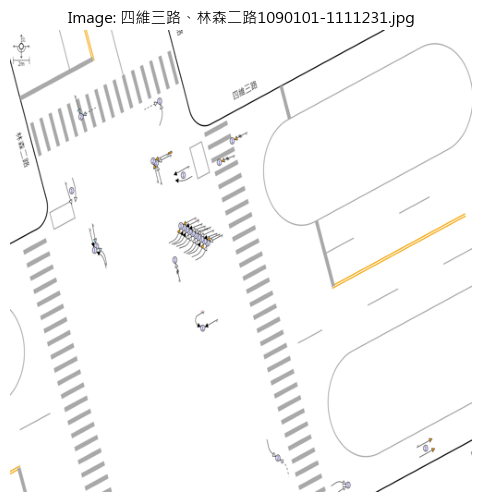

In [9]:
import random 
from PIL import Image

img_path = "images/真實碰撞構圖/四維三路、林森二路1090101-1111231.jpg"
show_image(img_path)

  0%|          | 0/22 [00:00<?, ?it/s]

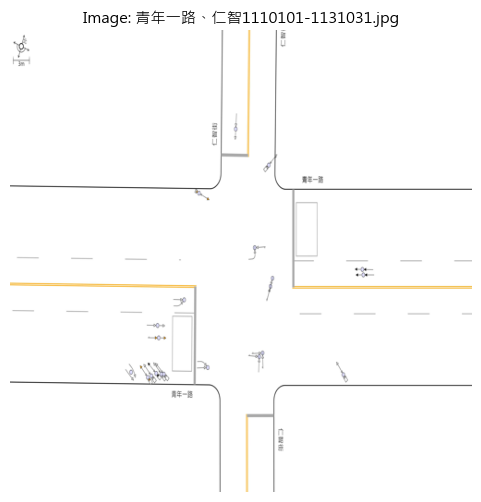

1.連續事件數共7件，一方車由西往南方向右轉，另一方車由西往東方向直行，兩車在西側路口近端發生右轉側撞
2.一方車由南往西方向左轉，另一方車由北往南方向直行，兩車在路口中端發生左轉穿越側撞
3.一方車由西往北方向左轉，另一方車由西往東方向直行，兩車在西側路段(往東)發生左轉追撞
4.一方車由南往西方向左轉，另一方車由南往北方向直行，兩車在南側路段(往北)發生左轉追撞
5.一方車由南往西方向左轉，另一方車由南往北方向直行，兩車在南側鄰近路口發生左轉追撞
6.一方車由北往東方向左轉，另一方車由北往南方向直行，兩車在北側路段(往南)發生左轉追撞
7.一方車由南往西方向左轉，另一方車由南往北方向直行，兩車在北側路段(往北)發生左轉追撞
8.一方車由西往北方向左轉，另一方車由西往東方向直行，兩車在東側路段(往東)發生左轉追撞
9.一方車由東往南方向左轉，另一方車由東往西方向直行，兩車在東側鄰近路口發生左轉追撞
10.一方車由北往東方向左轉，另一方車由北往南方向直行，兩車在北側鄰近路口發生左轉追撞
11.一方車由東往南方向左轉，另一方車由東往西方向直行，兩車在東側路段(往西)發生左轉追撞
12.一方車由西往北方向左轉，另一方車由西往東方向直行，兩車在東側路口近端發生左轉側撞
13.一方車由南往北方向直行，另一方車由西往東方向直行，兩車在東側路口近端發生右側交叉撞
14.一方車由北往東方向左轉，另一方車由北往南方向直行，兩車在南側路段(往南)發生左轉追撞
15.一方車由東往西方向直行，另一方車由北往西方向右轉，兩車在西側路口遠端發生右轉匯入側撞
16.一方車由南往西方向左轉，另一方車由南往北方向直行，兩車在南側路口近端發生左轉側撞


  5%|▍         | 1/22 [00:14<04:55, 14.08s/it]

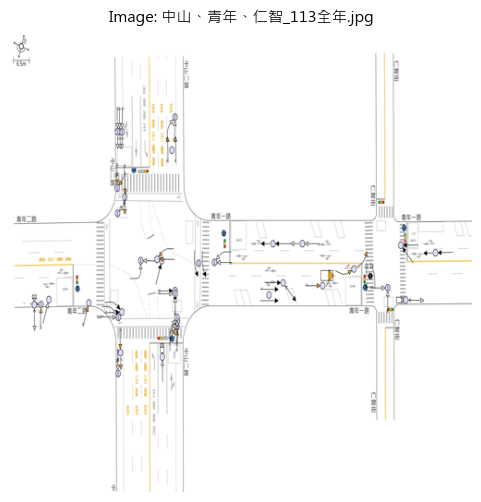

1.連續事件數共6件，一方車由北往東方向左轉，另一方車由北往南方向直行，兩車在北側路段(往南)發生左轉追撞
2.一方車由南往西方向左轉，另一方車由北往南方向直行，兩車在路口中端發生左轉穿越側撞
3.一方車由西往北方向左轉，另一方車由西往東方向直行，兩車在西側路段(往東)發生左轉追撞
4.一方車由南往西方向左轉，另一方車由南往北方向直行，兩車在南側路段(往北)發生左轉追撞
5.一方車由西往北方向左轉，另一方車由西往東方向直行，兩車在東側路段(往東)發生左轉追撞
6.一方車由南往西方向左轉，另一方車由南往北方向直行，兩車在南側鄰近路口發生左轉追撞
7.一方車由北往東方向左轉，另一方車由北往南方向直行，兩車在北側鄰近路口發生左轉追撞
8.一方車由西往北方向左轉，另一方車由西往東方向直行，兩車在西側鄰近路口發生左轉追撞
9.一方車由東往南方向左轉，另一方車由東往西方向直行，兩車在東側鄰近路口發生左轉追撞
10.一方車由南往西方向左轉，另一方車由南往北方向直行，兩車在北側路段(往北)發生左轉追撞
11.一方車由東往西方向直行，另一方車由北往西方向右轉，兩車在西側路口遠端發生右轉匯入側撞
12.一方車由西往北方向左轉，另一方車由西往東方向直行，兩車在西側路口近端發生左轉側撞
13.一方車由南往北方向直行，另一方車由西往東方向直行，兩車在東側路口近端發生右側交叉撞
1

  5%|▍         | 1/22 [00:24<08:44, 24.97s/it]


KeyboardInterrupt: 

In [10]:
from utils.gen_utils import custom_system_prompt
from utils.gen_utils import safe_json_parse
from glob import glob
from io import StringIO
from tqdm import tqdm

prompt = "你是一位專精台灣交通工程與交通安全的專家，請用繁體中文回答我的專業問題。請基於提供的肇事碰撞構圖，對路口進行分析並辨識肇事型態。"

model_id = client.models.list().data[0].id

llm_gens = []
for sample in tqdm(glob("images/真實碰撞構圖/*.jpg")):
    image_data = encode_image(sample)
    stream = client.chat.completions.create(
        model=model_id,
        messages=[
            {
                "role": "user",
                "content": [
                    {"type": "text", "text": prompt},
                    {"type": "image_url", "image_url": {"url": image_data}},
                ],
            },
        ],
        temperature=0.15,
        top_p=0.9,
        max_tokens=1000,  # thinking 模型需要更多 token 空間給推理過程
        stream=True,
        # 這裡不需要 tools/tool_choice，純文字問答分類即可
    )

    show_image(sample)

    reasoning_buf = StringIO()
    answer_buf = StringIO()
    for chunk in stream:
        delta = chunk.choices[0].delta

        # 若 vllm 有啟用 reasoning-parser，思考過程會在 reasoning_content，
        # 最終答案在 content；沒啟用的話兩者可能混在 content 裡（含 <think> 標籤）
        reasoning_piece = getattr(delta, "reasoning_content", None)
        if reasoning_piece:
            reasoning_buf.write(reasoning_piece)
            print(reasoning_piece, end="", flush=True)

        if delta.content:
            answer_buf.write(delta.content)
            print(delta.content, end="", flush=True)

    print()
    llm_gens.append({
        "reasoning": reasoning_buf.getvalue(),
        "answer": answer_buf.getvalue(),
    })

In [ ]:
import pandas as pd
from openpyxl import load_workbook
from openpyxl.drawing.image import Image as XLImage
from PIL import Image
from io import BytesIO
import os
from pathlib import Path
from glob import glob

def create_excel_report(image_paths, llm_outputs, output_path="交通肇事分析報告.xlsx"):
    """
    建立包含圖片與LLM分析結果的Excel報告
    
    參數:
        image_paths: 圖片路徑列表
        llm_outputs: LLM輸出結果列表
        output_path: 輸出Excel檔案路徑
    """
    # 建立資料框架
    data = {
        '編號': range(1, len(image_paths) + 1),
        '圖片檔名': [os.path.basename(path) for path in image_paths],
        '圖片路徑': image_paths,
        'LLM分析結果': llm_outputs
    }
    
    df = pd.DataFrame(data)
    
    # 儲存為Excel
    df.to_excel(output_path, index=False, engine='openpyxl')
    
    # 載入工作簿以插入圖片
    wb = load_workbook(output_path)
    ws = wb.active
    
    # 調整欄位寬度
    ws.column_dimensions['A'].width = 8   # 編號
    ws.column_dimensions['B'].width = 30  # 圖片檔名
    ws.column_dimensions['C'].width = 40  # 圖片路徑
    ws.column_dimensions['D'].width = 60  # LLM分析結果
    ws.column_dimensions['E'].width = 90  # 圖片欄位
    
    # 新增圖片欄位標題
    ws['E1'] = '碰撞構圖'
    
    # 設定每一列的高度（以像素為單位，約200像素）
    row_height_points = 500*0.9  # Excel的列高單位是點(points)
    
    # 插入圖片到Excel
    for idx, img_path in enumerate(image_paths, start=2):  # 從第2列開始（第1列是標題）
        try:
            # 載入並調整圖片大小
            img = Image.open(img_path)
            
            # 調整圖片尺寸（寬度200像素，保持比例）
            img.thumbnail((800, 800), Image.Resampling.LANCZOS)
            
            # 將圖片儲存到BytesIO
            img_byte_arr = BytesIO()
            img.save(img_byte_arr, format='PNG')
            img_byte_arr.seek(0)
            
            # 建立openpyxl圖片物件
            xl_img = XLImage(img_byte_arr)
            
            # 設定圖片位置（E欄）
            cell_address = f'E{idx}'
            ws.add_image(xl_img, cell_address)
            
            # 設定該列高度
            ws.row_dimensions[idx].height = row_height_points
            
            # 設定文字垂直置中
            ws[f'A{idx}'].alignment = ws[f'A{idx}'].alignment.copy(vertical='top')
            ws[f'B{idx}'].alignment = ws[f'B{idx}'].alignment.copy(vertical='top', wrap_text=True)
            ws[f'C{idx}'].alignment = ws[f'C{idx}'].alignment.copy(vertical='top', wrap_text=True)
            ws[f'D{idx}'].alignment = ws[f'D{idx}'].alignment.copy(vertical='top', wrap_text=True)
            
        except Exception as e:
            print(f"處理圖片 {img_path} 時發生錯誤: {e}")
    
    # 儲存工作簿
    wb.save(output_path)
    print(f"Excel報告已成功建立: {output_path}")
    
    return output_path

In [ ]:
# os.makedirs(inf_output_dir, exist_ok=True)
# # 建立 Excel 檔案
# create_excel_with_images_inf_data(data_list, llm_gens,
#     output_file=f'{inf_output_dir}/{basename}.xlsx')


# 取得所有圖片路徑
image_paths = glob("images/真實碰撞構圖/*.jpg")

# 確認資料數量一致
assert len(image_paths) == len(llm_gens), "圖片數量與LLM輸出數量不一致！"

# 生成Excel報告
create_excel_report(
    image_paths=image_paths,
    llm_outputs=llm_gens,
    output_path=f"交通肇事分析報告.xlsx"
)    